In [9]:
import os
import cv2
import numpy as np
import pandas as pd
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
def extract_features(image_path):
    img = cv2.imread(image_path)
    if img is None:
        print(f'[WARNING] Gagal membaca gambar: {image_path}')
        return None

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    r = img_rgb[:, :, 0]
    g = img_rgb[:, :, 1]
    b = img_rgb[:, :, 2]

    # Color moments: mean, standard deviation, skewness
    mean_r, mean_g, mean_b = float(np.mean(r)), float(np.mean(g)), float(np.mean(b))
    std_r, std_g, std_b = float(np.std(r)), float(np.std(g)), float(np.std(b))
    skew_r, skew_g, skew_b = float(skew(r.ravel())), float(skew(g.ravel())), float(skew(b.ravel()))

    # Tekstur GLCM (Gray-Level Co-occurrence Matrix)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    glcm = graycomatrix(gray, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256, symmetric=True, normed=True)
    contrast = float(graycoprops(glcm, 'contrast').mean())
    dissimilarity = float(graycoprops(glcm, 'dissimilarity').mean())
    homogeneity = float(graycoprops(glcm, 'homogeneity').mean())
    energy = float(graycoprops(glcm, 'energy').mean())
    correlation = float(graycoprops(glcm, 'correlation').mean())

    return {
        'mean_r': round(mean_r, 4),
        'mean_g': round(mean_g, 4),
        'mean_b': round(mean_b, 4),
        'std_r': round(std_r, 4),
        'std_g': round(std_g, 4),
        'std_b': round(std_b, 4),
        'skew_r': round(skew_r, 4),
        'skew_g': round(skew_g, 4),
        'skew_b': round(skew_b, 4),
        'contrast': round(contrast, 4),
        'dissimilarity': round(dissimilarity, 4),
        'homogeneity': round(homogeneity, 4),
        'energy': round(energy, 4),
        'correlation': round(correlation, 4)
    }

CSV_PATH = 'tabel_ekstraksi_ciri.csv'

# Gunakan cache CSV jika tersedia
if os.path.exists(CSV_PATH):
    print(f'Memuat dataset dari cache: {CSV_PATH}')
    df_features = pd.read_csv(CSV_PATH)
    print(f'Total sampel: {len(df_features)}')
else:
    print('Cache CSV tidak ditemukan, memulai ekstraksi fitur...')
    dataset_dir = '.'
    categories = ['bacterial_spot', 'healthy', 'powdery', 'virus']

    data_list = []
    for category in categories:
        cat_path = os.path.join(dataset_dir, category)
        if not os.path.isdir(cat_path):
            continue
        file_list = sorted(os.listdir(cat_path))
        for fname in file_list:
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                img_path = os.path.join(cat_path, fname)
                features = extract_features(img_path)
                if features is not None:
                    features['filename'] = fname
                    features['label'] = category
                    data_list.append(features)

    df_features = pd.DataFrame(data_list)
    cols = ['filename'] + [c for c in df_features.columns if c not in ['filename', 'label']] + ['label']
    df_features = df_features[cols]
    df_features.to_csv(CSV_PATH, index=False)
    print(f'Ekstraksi selesai. Total sampel: {len(df_features)}')

df_features.head(10)

Memuat dataset dari cache: tabel_ekstraksi_ciri.csv
Total sampel: 280


,filename,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,contrast,dissimilarity,homogeneity,energy,correlation,label
0,dde8f28e-38a3-4736-a44b-e37c28b8acd8___UF.GRC_...,118.7218,125.7633,86.4062,26.9622,31.0318,37.6269,-0.2086,0.0009,-0.2866,83.7150,6.2229,0.1797,0.0226,0.9383,bacterial_spot
1,ddfa387b-e1ba-4033-aea8-e6644c19b0fa___GCREC_B...,104.8522,114.7834,90.7824,49.4723,29.7870,50.2819,-0.1072,-0.3101,-0.1377,236.8892,10.7123,0.1179,0.0145,0.9134,bacterial_spot
2,de0200a0-173c-401f-827b-2a12d639a744___GCREC_B...,96.9747,104.6843,97.0058,42.2189,28.5202,36.5217,-0.0197,0.0085,0.0348,135.2940,8.0578,0.1513,0.0189,0.9385,bacterial_spot
3,de0d63c7-a1a2-43e0-9316-44381a5cb46a___GCREC_B...,103.1367,110.3696,98.0242,47.7421,35.4245,49.1796,-0.1609,-0.4956,-0.1902,193.1837,9.1219,0.1546,0.0170,0.9399,bacterial_spot
4,dea314b1-624c-492d-9eb0-965a34bf89c7___GCREC_B...,94.9002,104.9703,94.1988,47.5488,33.8723,43.3808,0.1587,0.2310,0.2334,102.5498,6.9236,0.1653,0.0205,0.9657,bacterial_spot
5,dec2db16-8bae-42e0-9b02-8e3d9f0793cc___GCREC_B...,93.3739,99.5052,87.7116,47.8537,33.8628,42.6001,0.1002,0.1402,0.1000,171.1265,8.6523,0.1474,0.0177,0.9429,bacterial_spot
6,df2c5959-402f-488c-8e9f-93d3a0cee4dd___UF.GRC_...,121.4051,129.3326,97.8020,22.5538,22.1457,37.1979,-0.5381,-0.8593,-0.1536,107.6701,7.1670,0.1620,0.0230,0.8868,bacterial_spot
7,df2cde45-b06c-421e-b0b9-955bf8b8f2e7___GCREC_B...,95.0645,99.8334,93.1848,42.1517,29.2525,37.2505,-0.0588,0.0936,0.0259,160.0283,9.0324,0.1293,0.0181,0.9296,bacterial_spot
8,df4ce90b-64df-4ed3-8978-bc9c619bdb57___GCREC_B...,98.9390,104.3231,92.4372,41.6179,31.5056,39.0963,0.1711,-0.0372,0.1145,170.8896,9.1021,0.1264,0.0162,0.9290,bacterial_spot
9,dfa62ef3-e71a-49c9-b3fc-6b1c72fa3408___GCREC_B...,97.2979,107.9845,89.8332,40.9720,25.6955,41.1233,0.0242,-0.0807,0.0891,135.7297,8.1608,0.1399,0.0183,0.9308,bacterial_spot


In [11]:
X = df_features.drop(columns=['filename', 'label'])
y = df_features['label']

# Stratified split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Jumlah Data Train: {X_train.shape[0]}')
print(f'Jumlah Data Test : {X_test.shape[0]}')
print(f'Jumlah Fitur     : {X_train.shape[1]}')
print('Distribusi kelas (train):')
print(y_train.value_counts().to_string())

Jumlah Data Train: 224
Jumlah Data Test : 56
Jumlah Fitur     : 14
Distribusi kelas (train):
label
healthy           56
bacterial_spot    56
powdery           56
virus             56


In [12]:
models = {
    'Support Vector Machine (SVM)': SVC(kernel='rbf', C=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=5)
}

trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    trained_models[name] = model
    predictions[name] = y_pred
    print(f'Model {name} selesai dilatih.')

Model Support Vector Machine (SVM) selesai dilatih.
Model Random Forest selesai dilatih.
Model K-Nearest Neighbors (KNN) selesai dilatih.


In [13]:
eval_results = []

for name in models.keys():
    y_pred = predictions[name]
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    eval_results.append({
        'Metode Klasifikasi': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

df_eval = pd.DataFrame(eval_results)
print('Tabel Evaluation Matrix (Weighted Average):')
display(df_eval)

Tabel Evaluation Matrix (Weighted Average):


,Metode Klasifikasi,Accuracy,Precision,Recall,F1-Score
0,Support Vector Machine (SVM),0.9821,0.9833,0.9821,0.9821
1,Random Forest,0.9643,0.9688,0.9643,0.9641
2,K-Nearest Neighbors (KNN),0.8571,0.8937,0.8571,0.8466


In [14]:
for name in models.keys():
    print("")
    print(f"Classification Report: {name}")
    print(classification_report(y_test, predictions[name]))



Classification Report: Support Vector Machine (SVM)
                precision    recall  f1-score   support

bacterial_spot       1.00      1.00      1.00        14
       healthy       0.93      1.00      0.97        14
       powdery       1.00      0.93      0.96        14
         virus       1.00      1.00      1.00        14

      accuracy                           0.98        56
     macro avg       0.98      0.98      0.98        56
  weighted avg       0.98      0.98      0.98        56


Classification Report: Random Forest
                precision    recall  f1-score   support

bacterial_spot       1.00      0.86      0.92        14
       healthy       1.00      1.00      1.00        14
       powdery       0.88      1.00      0.93        14
         virus       1.00      1.00      1.00        14

      accuracy                           0.96        56
     macro avg       0.97      0.96      0.96        56
  weighted avg       0.97      0.96      0.96        56


Classi

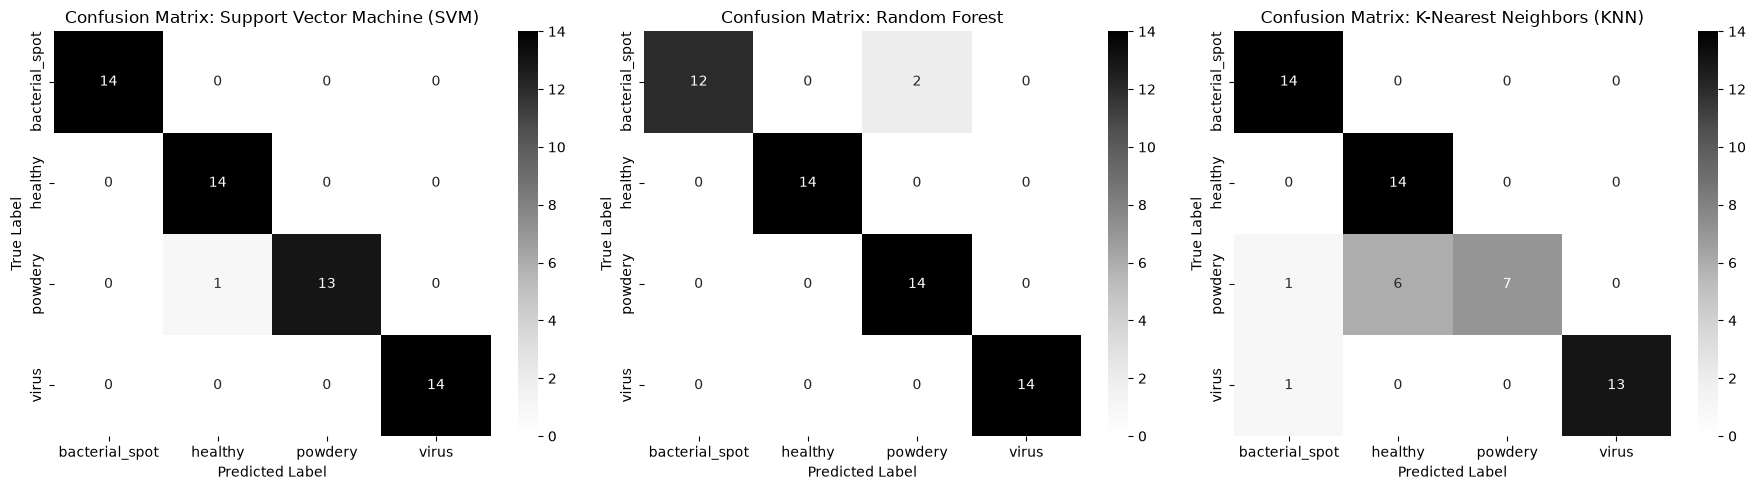

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
class_labels = sorted(y.unique())

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greys',
                xticklabels=class_labels, yticklabels=class_labels, ax=axes[idx])
    axes[idx].set_title(f'Confusion Matrix: {name}')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [16]:
y_all = LabelEncoder().fit_transform(y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Support Vector Machine (SVM)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=10, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    "K-Nearest Neighbors (KNN)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ]),
}

cv_results = []
for name, pipeline in cv_models.items():
    scores = cross_val_score(pipeline, X, y_all, cv=cv, scoring="accuracy")
    cv_results.append({
        "Metode": name,
        "CV Mean Accuracy": round(scores.mean(), 4),
        "CV Std (±)": round(scores.std(), 4),
        "Min": round(scores.min(), 4),
        "Max": round(scores.max(), 4),
    })
    print(f"{name}")
    print(f"  Fold scores : {[float(round(s, 4)) for s in scores]}")
    print(f"  Mean ± Std  : {scores.mean():.4f} ± {scores.std():.4f}")
    print("")

df_cv = pd.DataFrame(cv_results)
print("Tabel Ringkasan Cross-Validation:")
display(df_cv.set_index("Metode"))


Support Vector Machine (SVM)
  Fold scores : [0.9643, 0.9107, 0.9821, 0.9821, 0.9107]
  Mean ± Std  : 0.9500 ± 0.0327

Random Forest
  Fold scores : [0.9643, 0.8929, 0.9464, 0.9643, 0.8393]
  Mean ± Std  : 0.9214 ± 0.0487

K-Nearest Neighbors (KNN)
  Fold scores : [0.8393, 0.875, 0.875, 0.9286, 0.8214]
  Mean ± Std  : 0.8679 ± 0.0368

Tabel Ringkasan Cross-Validation:


,CV Mean Accuracy,CV Std (±),Min,Max
Metode,,,,
Support Vector Machine (SVM),0.9500,0.0327,0.9107,0.9821
Random Forest,0.9214,0.0487,0.8393,0.9643
K-Nearest Neighbors (KNN),0.8679,0.0368,0.8214,0.9286
